In [1]:
pip install -U mplhep

  Using cached mplhep-1.3.3-py3-none-any.whl.metadata (9.5 kB)


  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)


Using cached mplhep-1.3.3-py3-none-any.whl (93 kB)
Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (9.9 MB)


  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.8


    Uninstalling matplotlib-3.10.8:


...

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [matplotlib]

  Attempting uninstall: mplhep
    Found existing installation: mplhep 1.1.2
    Uninstalling mplhep-1.1.2:
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [matplotlib]

      Successfully uninstalled mplhep-1.1.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [matplotlib]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [mplhep]


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys
sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)
from sidm.tools import utilities #scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
utilities.set_plot_style()

In [6]:
title_name= "1 LJ CR" # title = r"1 LJ CR $\eta-\phi$ Veto"
ratio  = 6.616/62.061775847
# ratio = 1
# channel_name = "cr_Zmumu_noLJ" ##chnage the selection depending on what you want to plot 


channels=  [ 
    "cr_Zmumu_noLJ",
    "cr_Zmumu_noLJ_prompt",
    "cr_Zmumu_noLJ_displaced",
           ]
TT = functions.get_bg_file_names("TTJets")
DY = functions.get_bg_file_names("DYJetsToLL")
QCD = functions.get_bg_file_names("QCD")
DB = functions.get_bg_file_names("Diboson")
data = functions.get_data_files()
data =  [x for x in data if "C" in x]


sum_data_dict = {}
sum_QCD_dict = {}
sum_DY_dict = {}
sum_TT_dict = {}
sum_DB_dict = {}

for channel_name in channels:
    folder_name = f"OutputFiles/{channel_name}"
    sum_data= utilities.sum_hist(data, folder_name)
    sum_QCD = utilities.sum_hist(QCD, folder_name)
    sum_TT  = utilities.sum_hist(TT,  folder_name)
    sum_DY  = utilities.sum_hist(DY, folder_name)
    sum_DB  = utilities.sum_hist(DB,  folder_name)

    sum_data_dict[channel_name] = sum_data
    sum_QCD_dict[channel_name] = sum_QCD
    sum_TT_dict[channel_name] = sum_TT
    sum_DY_dict[channel_name] = sum_DY
    sum_DB_dict[channel_name] = sum_DB

In [8]:
def plot_channel(histogram_list, channel_name, binning=1j):
    summed_QCD = sum_QCD_dict[channel_name]
    summed_TT = sum_TT_dict[channel_name]
    summed_DY = sum_DY_dict[channel_name]
    summed_DB = sum_DB_dict[channel_name]
    summed_data = sum_data_dict[channel_name]
    functions.plot_DataMC(histogram_list,
                      channel_name, 
                      summed_QCD, 
                      summed_TT, 
                      summed_DY, 
                      summed_DB, 
                      summed_data, 
                      ratio, binning=binning, 
                      file_name=f"{channel_name}_lj_pt", 
                         lumi=6.616)
    

cr_Zmumu_noLJ
muon_trkNumPixelHits


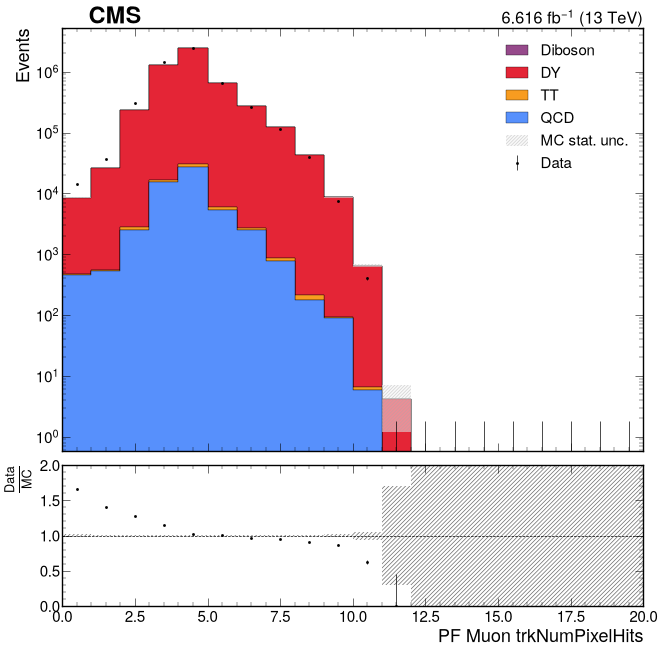

cr_Zmumu_noLJ_prompt
muon_trkNumPixelHits


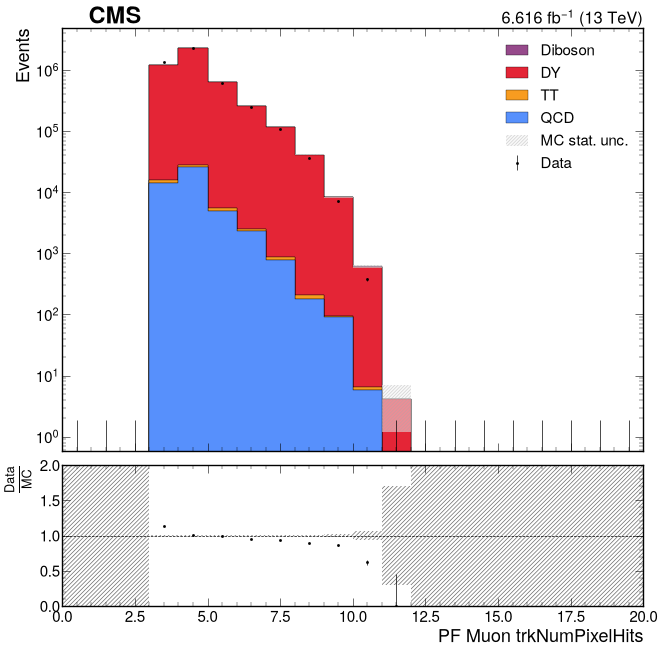

cr_Zmumu_noLJ_displaced
muon_trkNumPixelHits


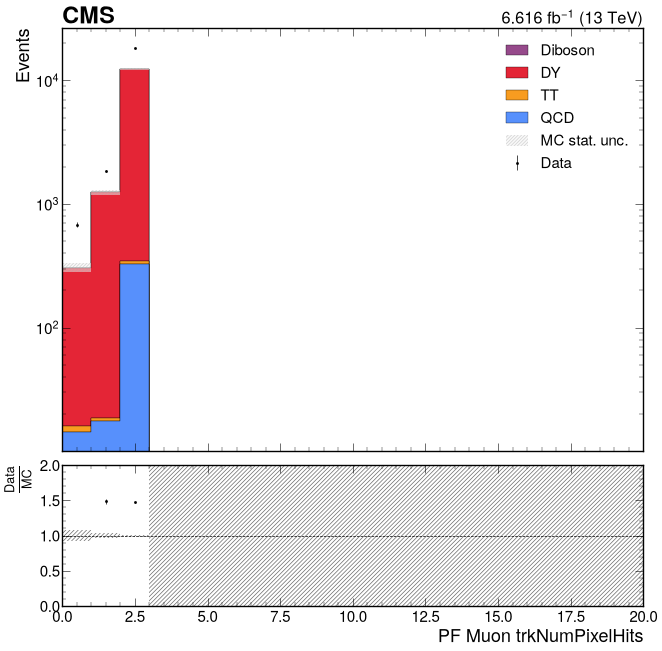

In [11]:
histogram_list  = [ 
"muon_trkNumPixelHits"
]

for channel_name in channels:
    print(channel_name)
    plot_channel(histogram_list, channel_name)

cr_Zmumu_noLJ
mu_lj_pt


mu_lj_pfMu_n


mu_lj_muonN


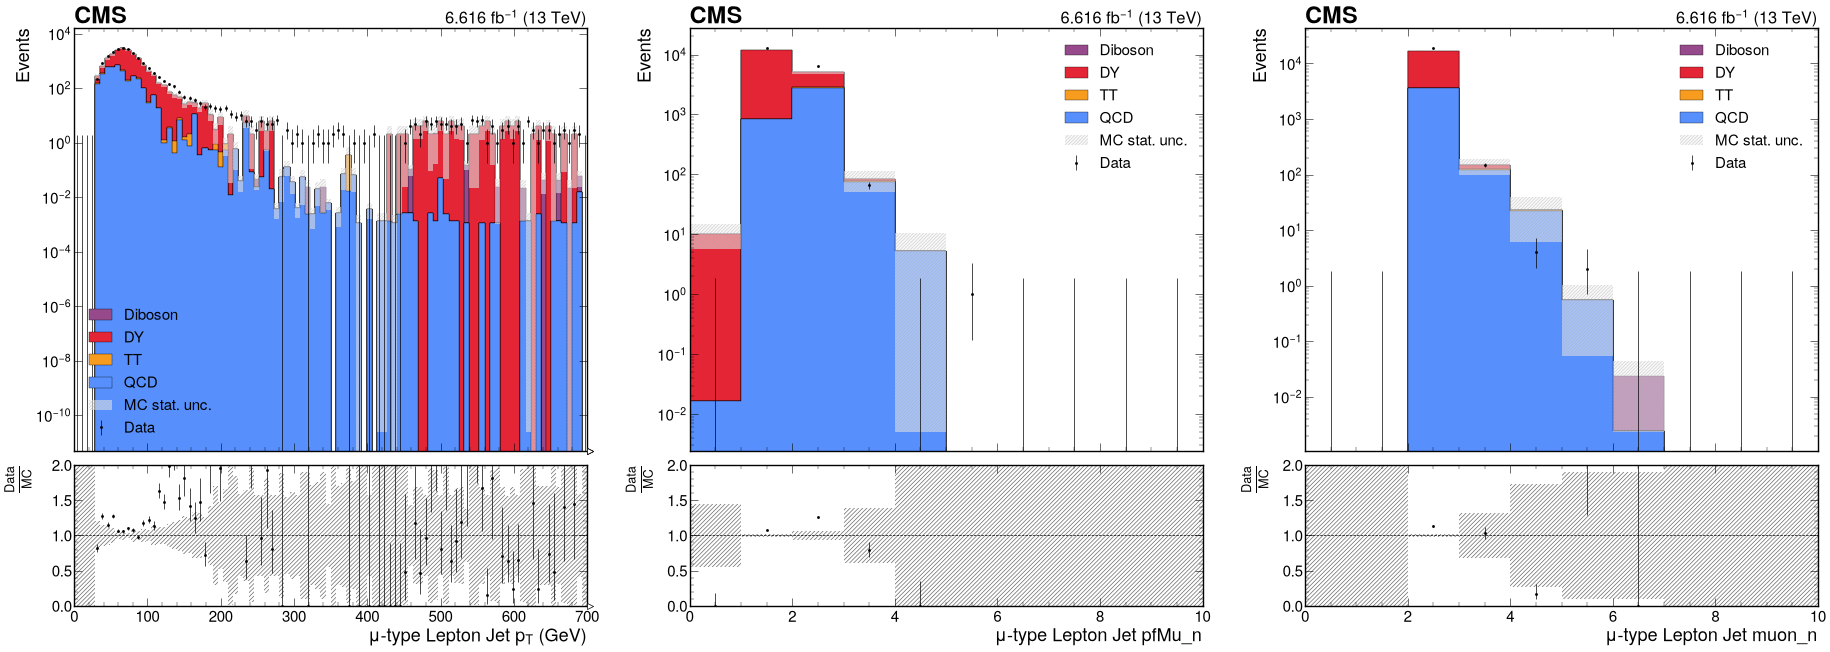

cr_Zmumu_noLJ_prompt
mu_lj_pt


mu_lj_pfMu_n


mu_lj_muonN


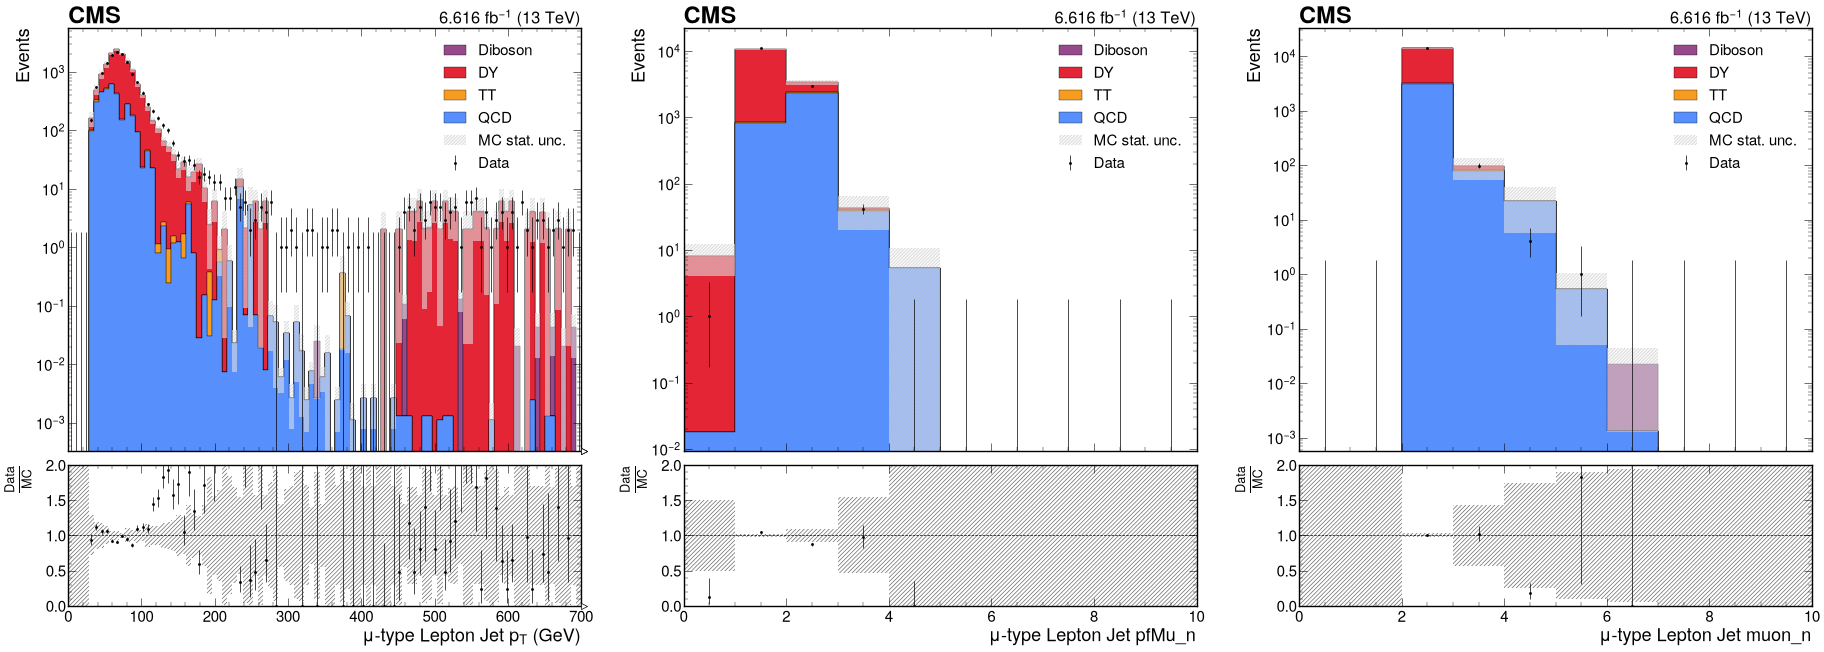

cr_Zmumu_noLJ_displaced
mu_lj_pt


mu_lj_pfMu_n


mu_lj_muonN


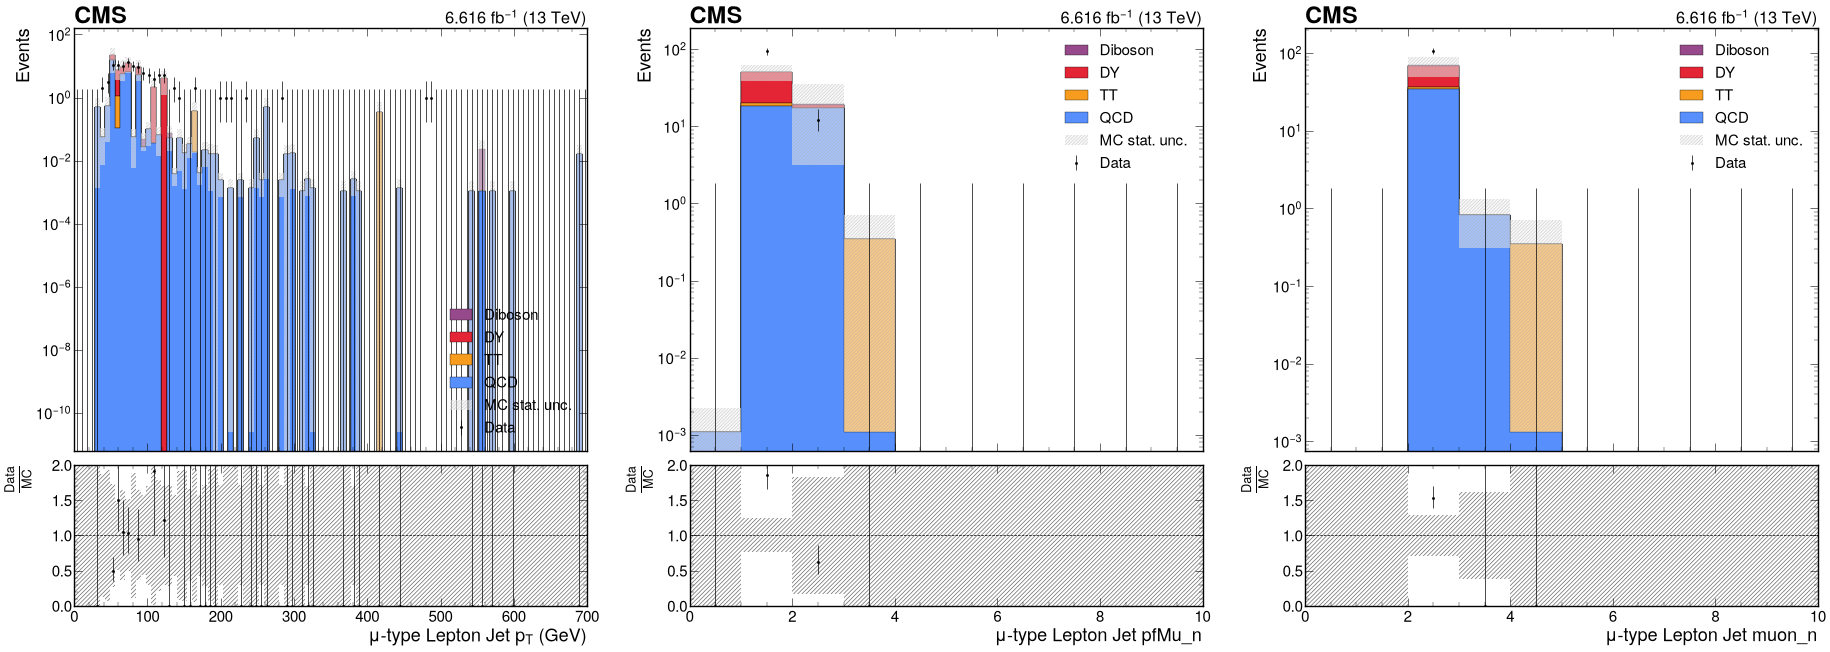

In [10]:
histogram_list  = [ 
'mu_lj_pt',
"mu_lj_pfMu_n",
"mu_lj_muonN"
]

for channel_name in channels:
    print(channel_name)
    plot_channel(histogram_list, channel_name)

cr_Zmumu_noLJ
mu0_mu1_pt


mu0_mu1_dR


mu0_mu1_dphi


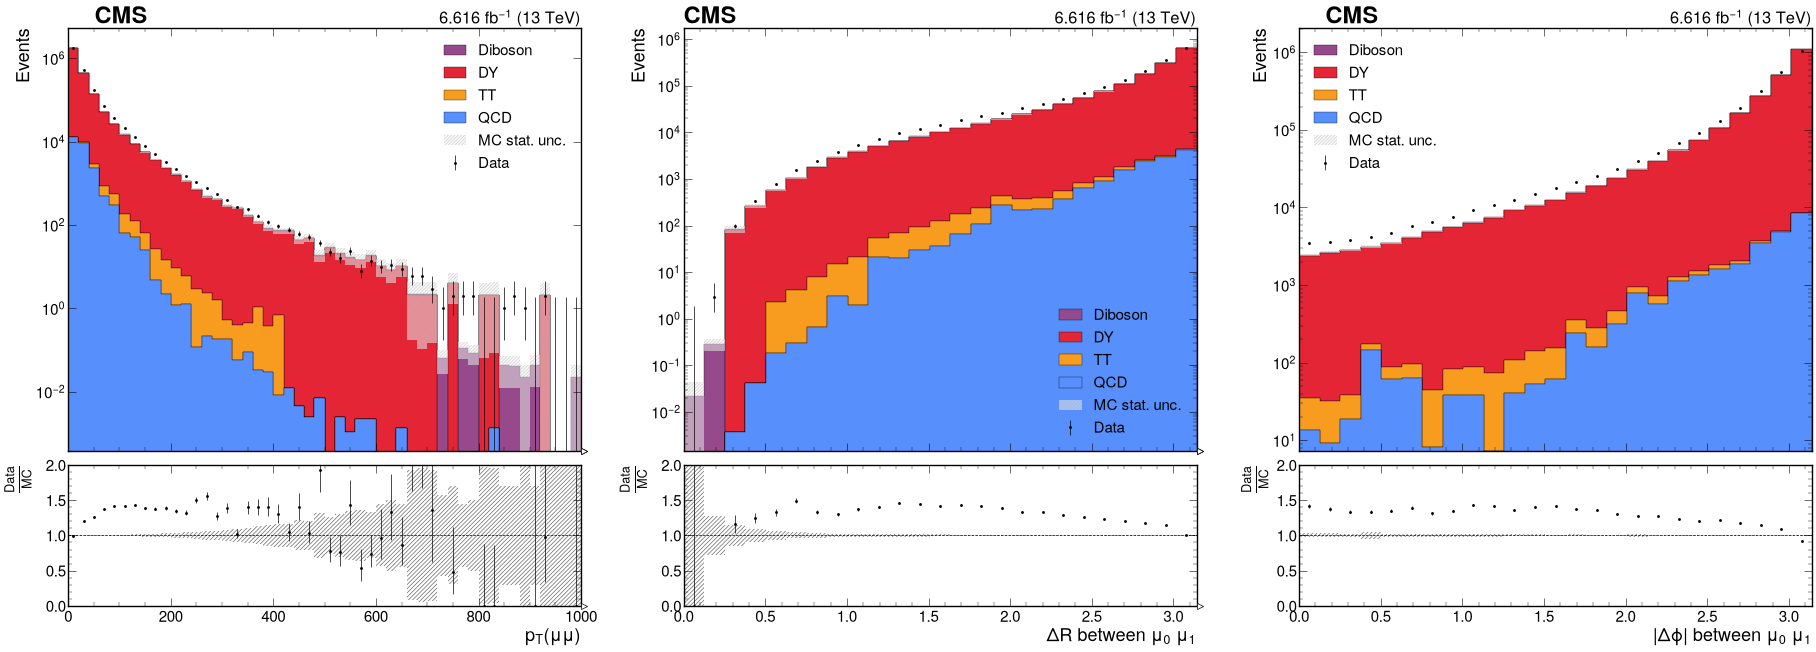

cr_Zmumu_noLJ_prompt
mu0_mu1_pt


mu0_mu1_dR


mu0_mu1_dphi


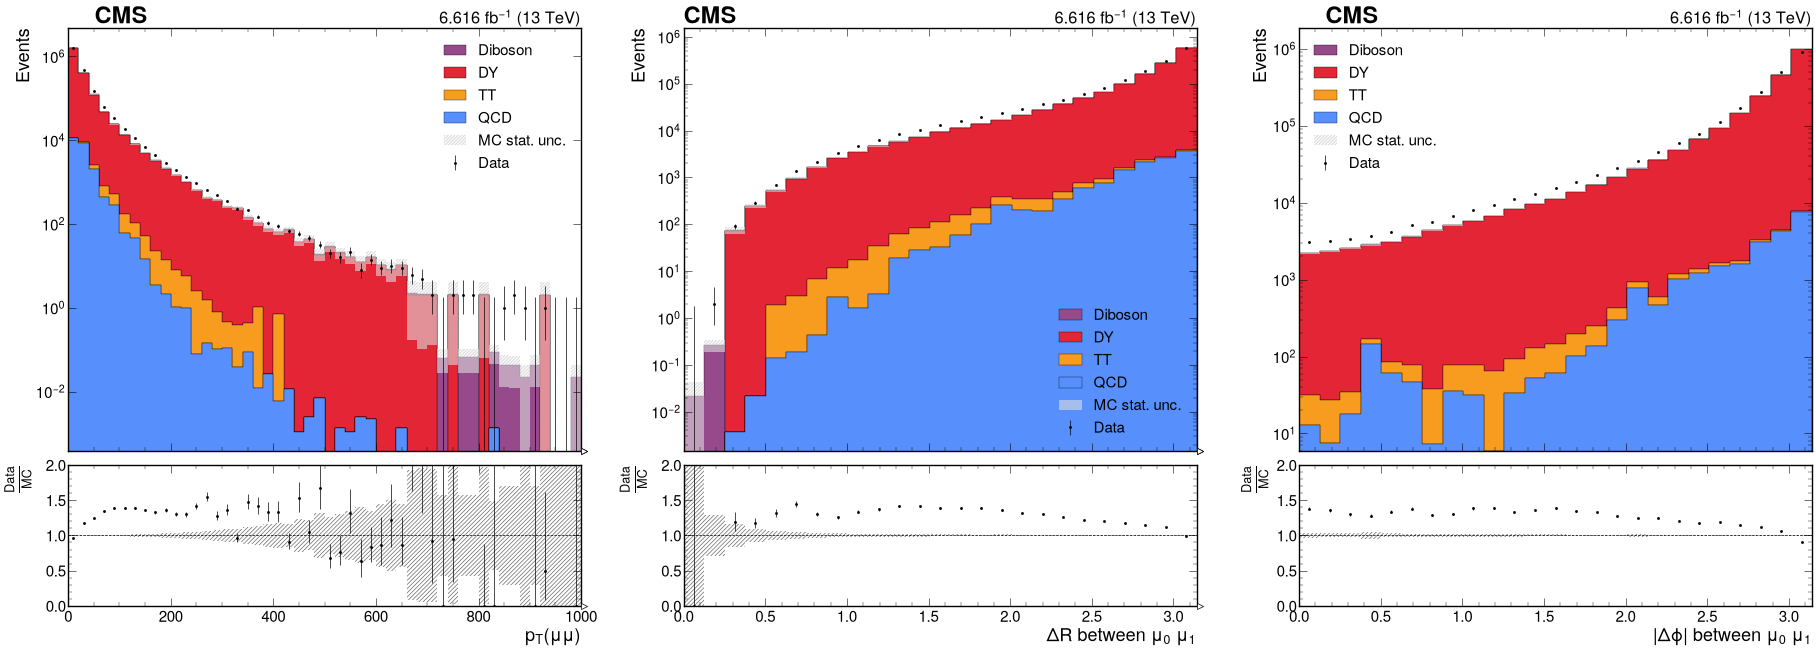

cr_Zmumu_noLJ_displaced
mu0_mu1_pt


mu0_mu1_dR


mu0_mu1_dphi


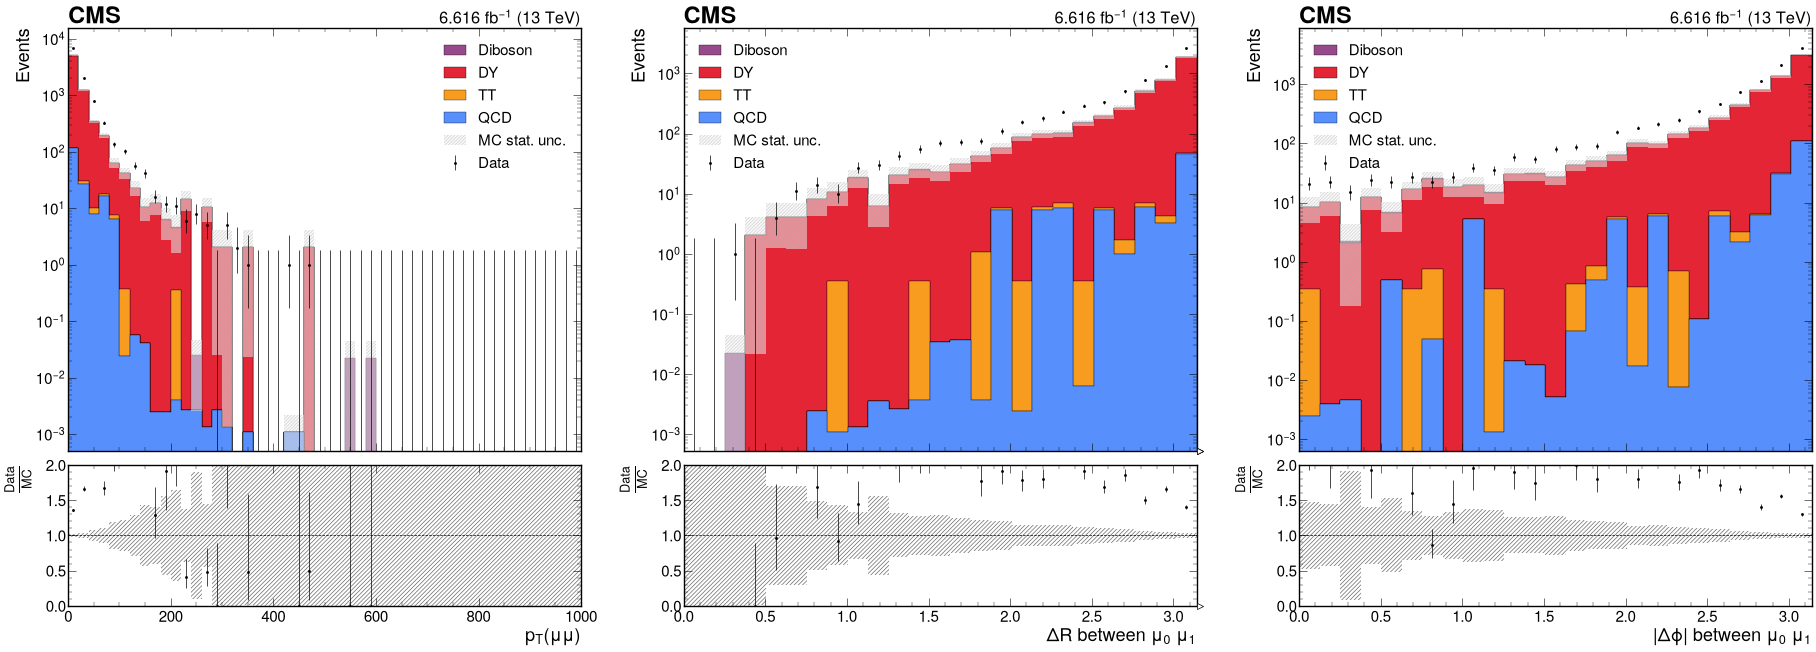

In [13]:

histogram_list  = [ 
'mu0_mu1_pt',
'mu0_mu1_dR',
'mu0_mu1_dphi'
]


for channel_name in channels:
    print(channel_name)
    plot_channel(histogram_list, channel_name, binning=2j)

cr_Zmumu_noLJ
jet0_muLj0_dR


jet1_muLj0_dR


jet0_muLj0_dPhi


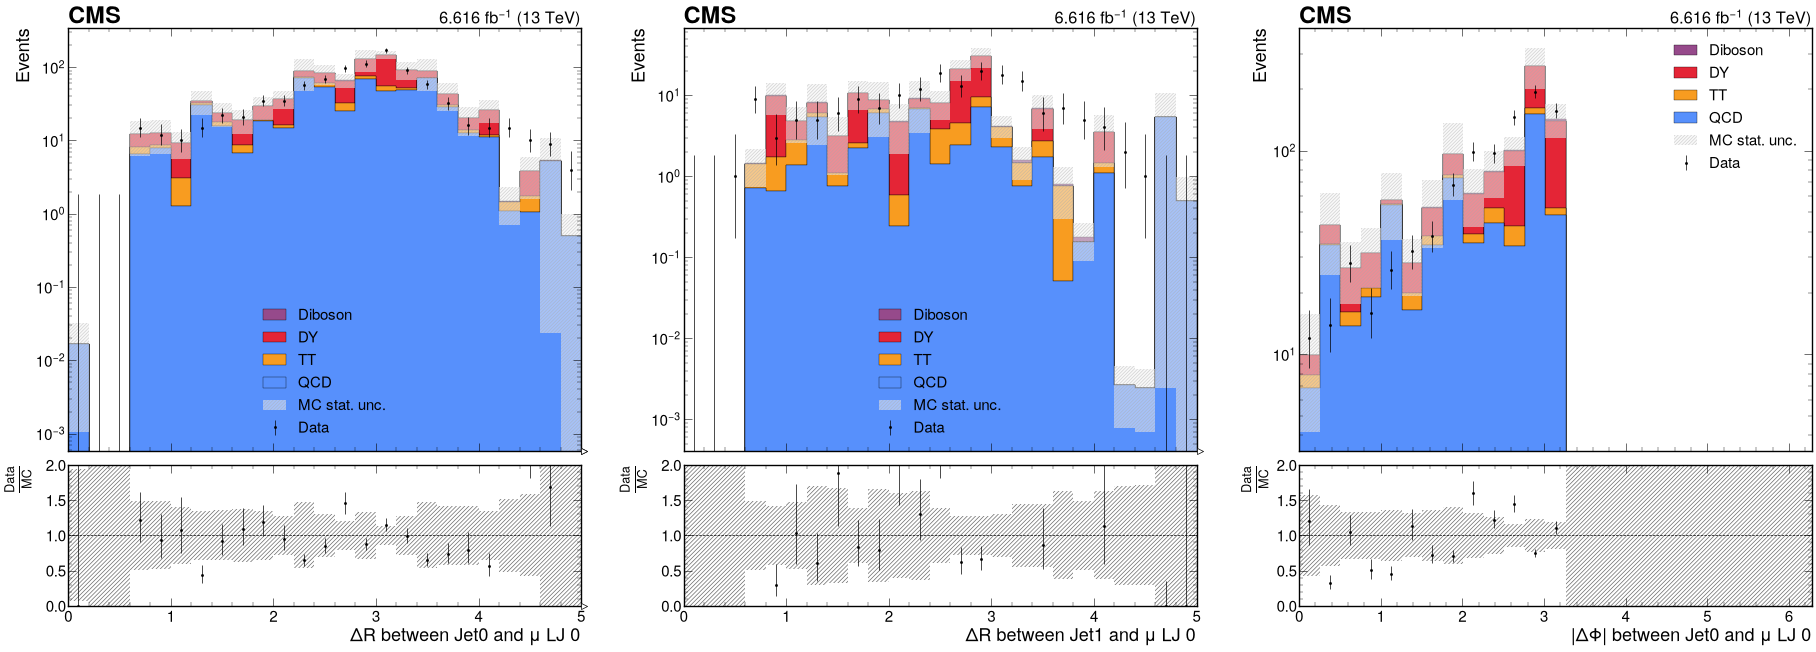

cr_Zmumu_noLJ_prompt
jet0_muLj0_dR


jet1_muLj0_dR


jet0_muLj0_dPhi


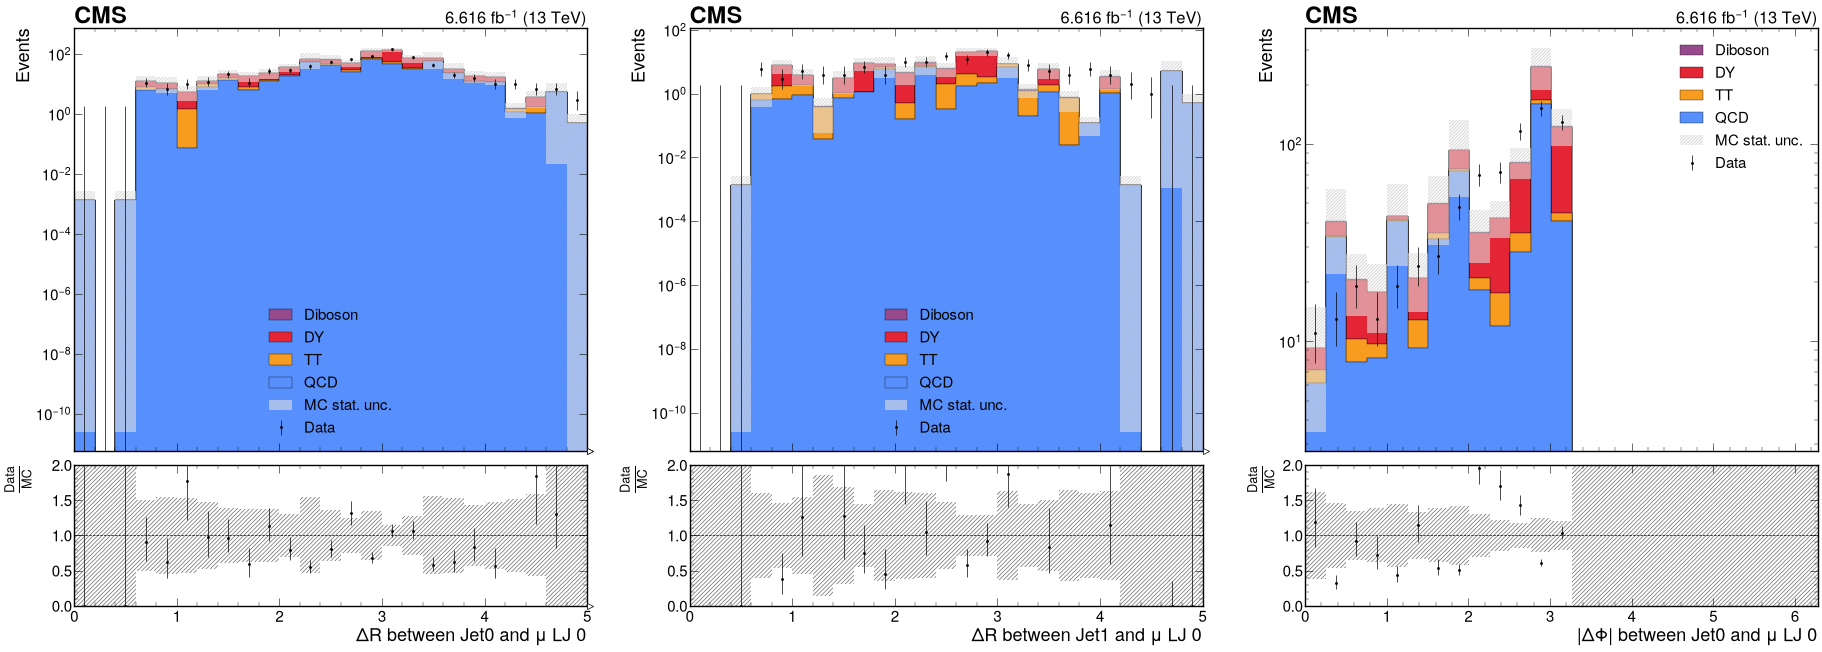

cr_Zmumu_noLJ_displaced
jet0_muLj0_dR


jet1_muLj0_dR


jet0_muLj0_dPhi


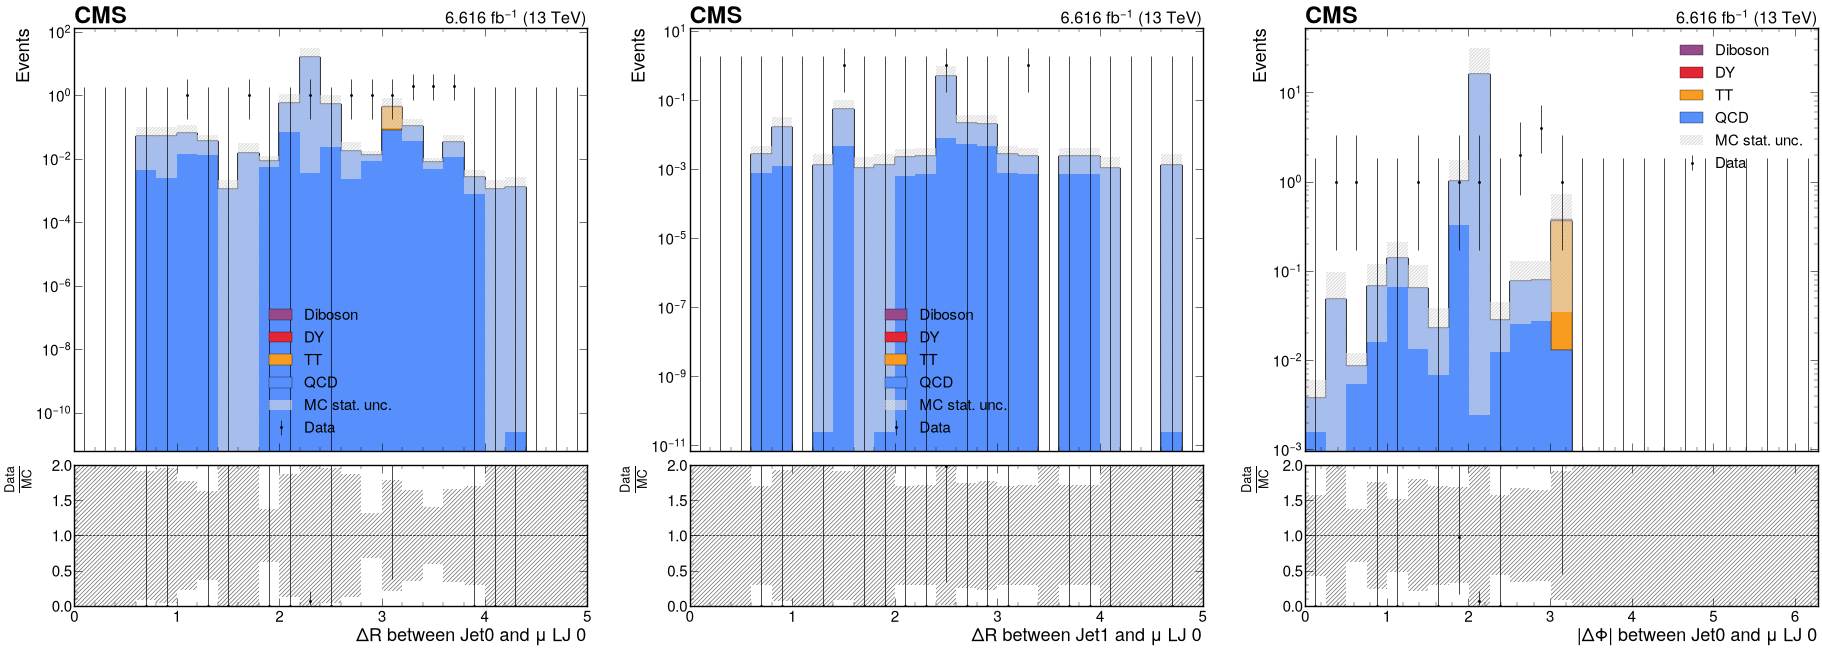

In [14]:


histogram_list  = [ 
'jet0_muLj0_dR',
'jet1_muLj0_dR',
'jet0_muLj0_dPhi',
]



for channel_name in channels:
    print(channel_name)
    plot_channel(histogram_list, channel_name, binning=2j)

cr_Zmumu_noLJ
jet_n


jet_pt


mu_lj_pt


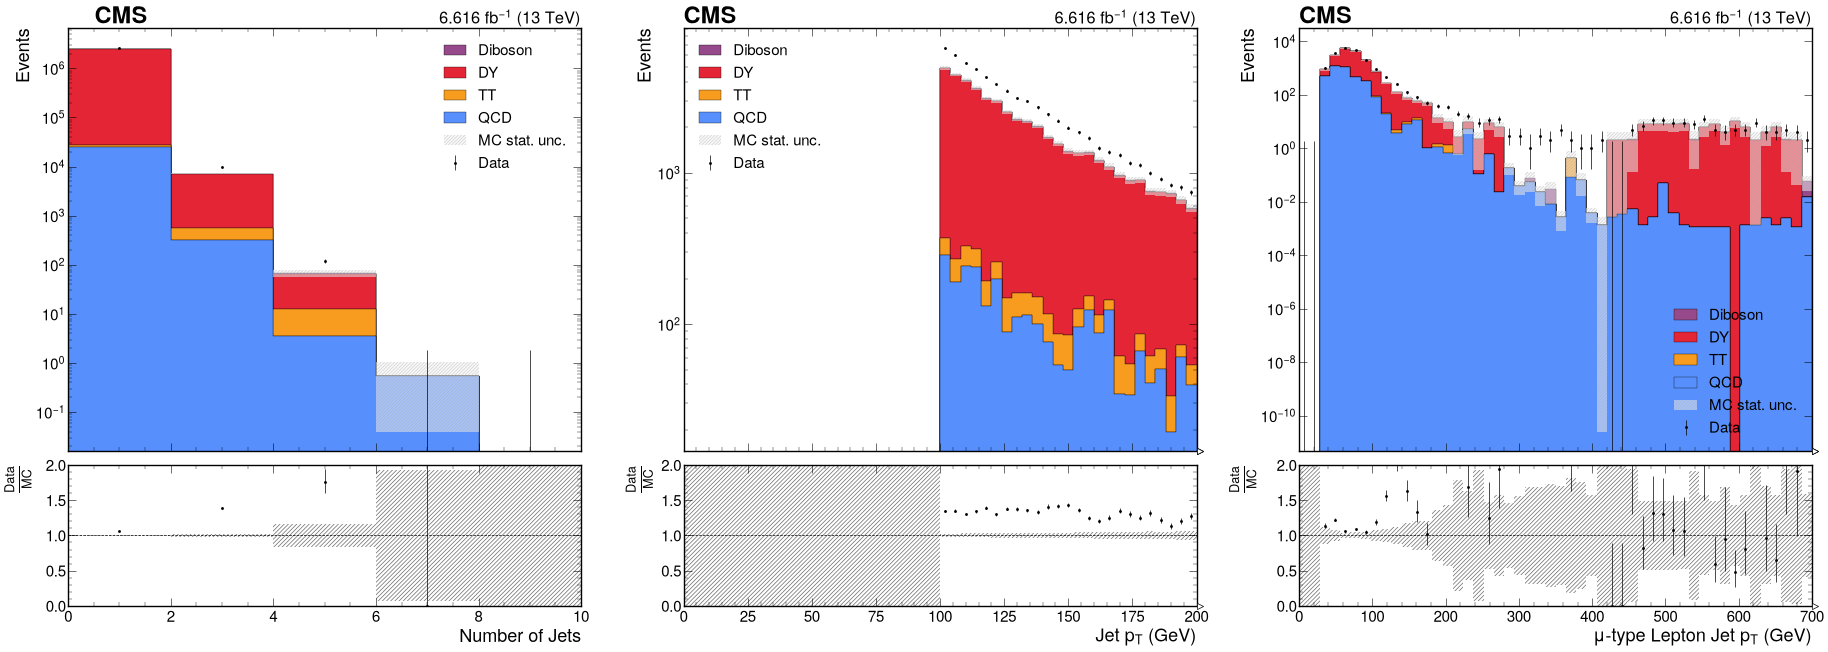

cr_Zmumu_noLJ_prompt
jet_n


jet_pt


mu_lj_pt


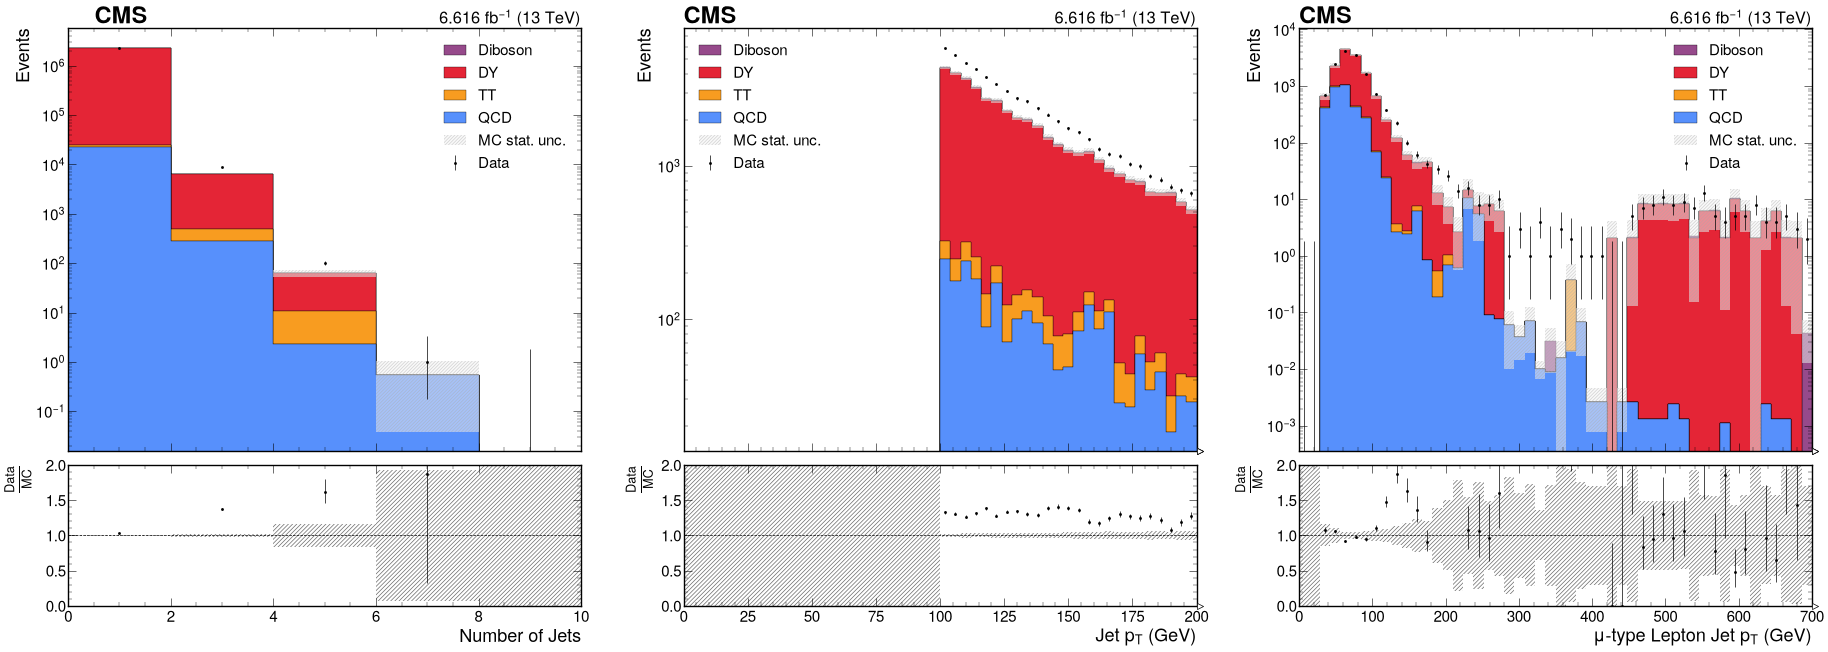

cr_Zmumu_noLJ_displaced
jet_n


jet_pt


mu_lj_pt


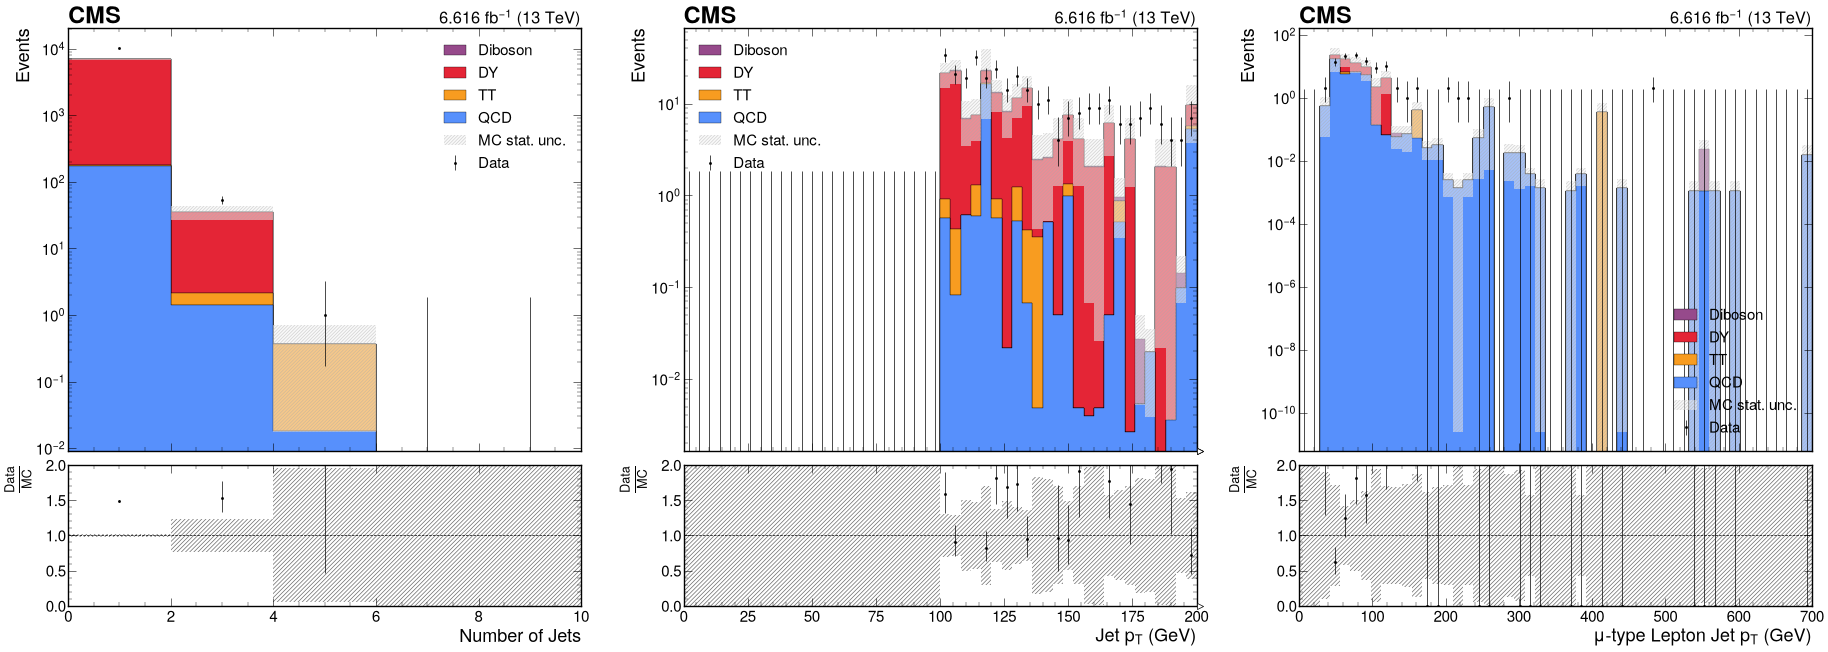

In [15]:
histogram_list  = [ 
'jet_n',
'jet_pt',
'mu_lj_pt',   
]
for channel_name in channels:
    print(channel_name)
    plot_channel(histogram_list, channel_name, binning=2j)